# 01 — Inventory & EDA (Phase 0–1)

Scope: inventory the 9 official files, check Combine-tracking coverage and NFL
outcome coverage, and decide the thesis. **No feature engineering or models here.**
Ends with the thesis lock memo (NEXT_STEPS.md §3).

Run `python scripts/convert_to_parquet.py` once before this notebook.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from src.config import ALL_TABLES, FIG_PATH, SEED
from src.io import load, scan, scan_game_tracking, parse_time, SCHEMAS, BOOL_AS_FLOAT
from src.nfl_features import play_frame, regular_season, wr_route_snaps, BREAKING_ROUTES, VERTICAL_ROUTES
from src.combine_features import sketch_break_metrics, player_best, SPEED_DIP_DRILLS
from src.plots import set_style, plot_drill_trace

np.random.seed(SEED)
set_style()
FIG_PATH.mkdir(exist_ok=True)
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_tbl_hide_dataframe_shape(True);

## 1. File inventory

Row counts come from the Parquet copies (streamed from the CSVs with the documented schema).

In [2]:
DOC_ROWS = {"players": 510, "combine_results": 510, "combine_tracking": 463_189,
            "player_career_successes": 510, "player_play": 316_338, "games": 1_002,
            "game_tracking_2023": 1_421_805, "game_tracking_2024": 3_042_118,
            "game_tracking_2025": 4_339_021}
inventory = pl.DataFrame([
    {"table": n, "rows": scan(n).select(pl.len()).collect().item(),
     "doc_rows": DOC_ROWS[n], "columns": len(scan(n).collect_schema())}
    for n in ALL_TABLES
]).with_columns((pl.col("rows") - pl.col("doc_rows")).alias("rows_minus_doc"))
inventory

table,rows,doc_rows,columns,rows_minus_doc
str,i64,i64,i64,i64
"""players""",510,510,10,0
"""combine_results""",510,510,18,0
"""combine_tracking""",463189,463189,14,0
"""player_career_successes""",510,510,9,0
"""player_play""",314197,316338,64,-2141
"""games""",1002,1002,7,0
"""game_tracking_2023""",3665443,1421805,12,2243638
"""game_tracking_2024""",7827944,3042118,12,4785826
"""game_tracking_2025""",11160903,4339021,12,6821882


**Deviations from `Data_Desctiption.MD` (data wins; recorded here, not silently fixed):**

- `player_play` has **314,197** records, not 316,338 (the CSV has 327,020 physical lines because
  some `play_description` values contain newlines inside quotes).
- `game_tracking_*` files are **~2.6× larger** than documented (3.67M / 7.83M / 11.16M rows).
  Line counts confirm the files are complete; the doc numbers are stale.
- `quick_pressure`, `unblocked_pressure`, `recovered_fumble`, `tackle_for_loss` are documented as
  float64 but stored as `TRUE/FALSE`. They are cast to 1.0/0.0 in Parquet to match the doc.
- `player_play` includes **preseason (`PRE`) games**; `games.csv` doc only mentions REG/POST.
- `combine_tracking`: BALL frames carry the receiver's `nfl_id` (doc says null). `a` is an
  unsigned magnitude (never < 0), so deceleration must be derived from Δspeed.
- `pass_result` uses an empty string (not null) on non-pass plays.
- Combine `dis` is **not** distance per frame. It behaves like the squared step (dis / step² ≈ 1),
  so summing it under-counts path length. Path length must come from `x`/`y`. (Game-tracking `dis` is normal.)
- 2025 Combine `x` values are off the 1/30-yard grid that 2023–2024 use, which points to a processing change
  between years. Check Phase 2 metrics by draft class.

In [3]:
pp_all = play_frame()
print("season_type:", dict(pp_all["season_type"].value_counts().iter_rows()))
print("play_nullified_by_penalty:", dict(pp_all["play_nullified_by_penalty"].value_counts().iter_rows()))
ct = load("combine_tracking")
print("min a:", ct["a"].min(), "| BALL frames with null nfl_id:",
      ct.filter(pl.col("entity_type") == "BALL")["nfl_id"].null_count())
steps = (ct.filter(pl.col("entity_type") == "PLAYER").sort("event_id", "time")
           .with_columns(((pl.col("x").diff() ** 2 + pl.col("y").diff() ** 2).sqrt()).over("event_id").alias("step"))
           .filter(pl.col("step") > 0.05))
print(f"Combine dis/step median {(steps['dis'] / steps['step']).median():.2f} | "
      f"dis/step^2 median {(steps['dis'] / steps['step'] ** 2).median():.2f}")
grid = (ct.filter(pl.col("entity_type") == "PLAYER").group_by("draft_year")
          .agg(((pl.col("x") * 30 - (pl.col("x") * 30).round()).abs() < 1e-4).mean().round(2).alias("x_on_1_30_grid"))
          .sort("draft_year"))
print("x on 1/30-yd grid by Combine year:", dict(grid.iter_rows()))

season_type: {'POST': 13169, 'PRE': 51759, 'REG': 249269}
play_nullified_by_penalty: {'Y': 12490, 'N': 301707}
min a: 0.0 | BALL frames with null nfl_id: 0
Combine dis/step median 0.47 | dis/step^2 median 0.97
x on 1/30-yd grid by Combine year: {2023: 1.0, 2024: 1.0, 2025: 0.0}


## 2. Players & Combine results

In [4]:
players = load("players")
cr = load("combine_results")
pc = players.join(cr.drop("draft_year"), on="nfl_id", how="left")

(pc.with_columns(pl.when(pl.col("draft_round").is_null()).then(pl.lit("UDFA"))
                   .otherwise(pl.format("R{}", pl.col("draft_round"))).alias("round"))
   .pivot(on="draft_year", index="combine_position", values="nfl_id", aggregate_function="len",
          sort_columns=True)
   .with_columns(pl.sum_horizontal(pl.exclude("combine_position")).alias("total"))
   .sort("total", descending=True))

combine_position,2023,2024,2025,total
str,u32,u32,u32,u32
"""DB""",35,50,37,122
"""OL""",37,46,38,121
"""DL""",37,37,44,118
"""WR""",39,31,37,107
"""TE""",12,13,17,42


In [5]:
# Roster position within each Combine position group
pc.group_by("combine_position", "nfl_position").len().sort("combine_position", "len", descending=[False, True])

combine_position,nfl_position,len
str,str,u32
"""DB""","""CB""",60
"""DB""","""SS""",28
"""DB""","""FS""",25
"""DB""","""DB""",5
"""DB""","""ILB""",2
"""DB""","""RB""",1
"""DB""","""MLB""",1
"""DL""","""DT""",47
"""DL""","""DE""",36


In [6]:
# Draft capital by Combine group (UDFA counted separately)
pc.group_by("combine_position").agg(
    pl.len().alias("n"),
    pl.col("draft_round").is_null().sum().alias("udfa"),
    (pl.col("draft_round") <= 2).sum().alias("rounds_1_2"),
    pl.col("draft_overall_pick").median().alias("median_pick"),
).sort("n", descending=True)

combine_position,n,udfa,rounds_1_2,median_pick
str,u32,u32,u32,f64
"""DB""",122,25,18,140.0
"""OL""",121,32,34,97.0
"""DL""",118,29,23,123.0
"""WR""",107,30,18,125.0
"""TE""",42,11,4,162.0


**Stopwatch opt-outs.** Share of each Combine group with a *missing* traditional time.
Agility drills (3-cone, shuttle) are skipped by most WRs and DBs, so a stopwatch-only
agility evaluation is unavailable for most of the players we care about.

In [7]:
STOPWATCH = ["forty", "ten_yd_split", "three_cone", "short_shuttle", "vertical", "broad_jump", "ngs_athleticism_score"]
optout = pc.group_by("combine_position").agg(
    pl.len().alias("n"), *[pl.col(c).is_null().mean().round(2).alias(c) for c in STOPWATCH]
).sort("n", descending=True)
optout

combine_position,n,forty,ten_yd_split,three_cone,short_shuttle,vertical,broad_jump,ngs_athleticism_score
str,u32,f64,f64,f64,f64,f64,f64,f64
"""DB""",122,0.15,0.15,0.8,0.73,0.14,0.2,0.0
"""OL""",121,0.21,0.21,0.5,0.47,0.17,0.19,0.0
"""DL""",118,0.2,0.2,0.64,0.61,0.14,0.18,0.0
"""WR""",107,0.09,0.09,0.69,0.64,0.1,0.11,0.0
"""TE""",42,0.19,0.19,0.57,0.52,0.17,0.17,0.0


## 3. Combine tracking

### 3a. Sampling sanity

In [8]:
ctp = ct.filter(pl.col("entity_type") == "PLAYER")
dts = (ct.sort("event_id", "entity_type", "time")
         .with_columns(parse_time().alias("ts"))
         .with_columns(pl.col("ts").diff().over("event_id", "entity_type").dt.total_milliseconds().alias("dt_ms")))
print("frame spacing (ms):", dict(dts["dt_ms"].drop_nulls().value_counts().iter_rows()))
print("events:", ct["event_id"].n_unique(), "| players:", ctp["nfl_id"].n_unique())
print("events with >1 player:", ctp.group_by("event_id").agg(pl.col("nfl_id").n_unique()).filter(pl.col("nfl_id") > 1).height)
ctp.select(
    [pl.col(c).quantile(q).alias(f"{c}_p{int(q*1000)/10:g}") for c in ["s", "a", "dis"] for q in (0.5, 0.999)]
    + [pl.col("s").max().alias("s_max"), pl.col("a").max().alias("a_max"),
       ((pl.col("y") < 0) | (pl.col("y") > 53.3)).mean().round(3).alias("share_y_outside_0_53")]
)

frame spacing (ms): {100: 456328}
events: 6310 | players: 510
events with >1 player: 0


s_p50,s_p99.9,a_p50,a_p99.9,dis_p50,dis_p99.9,s_max,a_max,share_y_outside_0_53
f64,f64,f64,f64,f64,f64,f64,f64,f64
4.976667,11.316667,2.566155,8.544615,0.217823,1.284444,11.854232,10.717722,0.115


Every consecutive frame is exactly 0.10 s apart, every event has exactly one player, and
player speeds and accelerations are physically plausible (max 11.9 yd/s and 10.7 yd/s²; the larger values belong to BALL frames). About 11% of frames fall
outside the 0–53.3 y range: Combine drills are not run on game-field coordinates, so
geometry features must be **relative to each attempt's own start**, not to field bounds.

### 3b. Drill catalog (`drill_type` × `drill_name` × `combine_position`)

In [9]:
catalog = (ctp.join(cr.select("nfl_id", "combine_position"), on="nfl_id", how="left")
   .group_by("drill_type", "drill_name", "combine_position")
   .agg(pl.col("event_id").n_unique().alias("events"),
        pl.col("nfl_id").n_unique().alias("players"),
        (pl.len() / pl.col("event_id").n_unique()).round(0).alias("frames_per_event"))
   .sort("drill_type", "events", descending=[False, True]))
catalog.write_csv(FIG_PATH / "drill_catalog.csv")
print(f"{catalog.height} drill x position rows (full table saved to figures/drill_catalog.csv)")
catalog.group_by("drill_type").agg(
    pl.col("drill_name").n_unique().alias("drill_names"),
    pl.col("events").sum(), pl.col("players").max().alias("max_players_in_one_drill"),
    pl.col("combine_position").unique().sort().str.join("/").alias("positions"),
).sort("events", descending=True)

74 drill x position rows (full table saved to figures/drill_catalog.csv)


drill_type,drill_names,events,max_players_in_one_drill,positions
str,u32,u32,u32,str
"""SKILL_DRILLS_WR""",15,1529,107,"""WR"""
"""SKILL_DRILLS_DB""",9,1170,122,"""DB"""
"""SKILL_DRILLS_DL""",11,1007,114,"""DL"""
"""SKILL_DRILLS_OL""",8,910,120,"""OL"""
"""FORTY_YARD_DASH""",1,793,102,"""DB/DL/OL/TE/WR"""
"""SKILL_DRILLS_TE""",10,438,42,"""TE"""
"""SHORT_SHUTTLE""",1,223,54,"""DB/DL/OL/TE/WR"""
"""THREE_CONE_DRILL""",1,203,48,"""DB/DL/OL/TE/WR"""
"""SKILL_DRILLS_LB""",6,37,4,"""DL"""


In [10]:
# WR route drills (the default thesis' Combine signal)
catalog.filter(pl.col("drill_type") == "SKILL_DRILLS_WR").drop("drill_type")

drill_name,combine_position,events,players,frames_per_event
str,str,u32,u32,f64
"""GAUNTLET_DRILL""","""WR""",200,107,91.0
"""DAGGER_ROUTE_LEFT""","""WR""",115,107,66.0
"""RED_ZONE_FADE_RIGHT""","""WR""",112,98,45.0
"""POST_CORNER_ROUTE_RIGHT""","""WR""",111,96,72.0
"""SLANT_ROUTE_LEFT""","""WR""",110,107,39.0
"""COMEBACK_ROUTE_RIGHT""","""WR""",110,98,60.0
"""CURL_ROUTE_RIGHT""","""WR""",110,103,56.0
"""SLOT_SAIL_ROUTE_RIGHT""","""WR""",106,98,70.0
"""GO_ROUTE_RIGHT""","""WR""",105,98,73.0


In [11]:
# DB and DL drills (backup theses)
catalog.filter(pl.col("drill_type").is_in(["SKILL_DRILLS_DB", "SKILL_DRILLS_DL"])).drop("frames_per_event")

drill_type,drill_name,combine_position,events,players
str,str,str,u32,u32
"""SKILL_DRILLS_DB""","""BACK_PEDAL_AND_TRANSITION_45_D…","""DB""",241,122
"""SKILL_DRILLS_DB""","""LINE_DRILL""","""DB""",167,85
"""SKILL_DRILLS_DB""","""BOX_DRILL""","""DB""",125,122
"""SKILL_DRILLS_DB""","""BACK_PEDAL_AND_90_DEGREE_BREAK…","""DB""",124,122
"""SKILL_DRILLS_DB""","""W_DRILL""","""DB""",124,121
"""SKILL_DRILLS_DB""","""GAUNTLET_DRILL""","""DB""",123,119
"""SKILL_DRILLS_DB""","""TERYL_AUSTIN_DRILL_2""","""DB""",113,111
"""SKILL_DRILLS_DB""","""TERYL_AUSTIN_DRILL_1""","""DB""",103,101
"""SKILL_DRILLS_DB""","""LINE""","""DB""",50,33


In [12]:
# Attempts per player x WR drill: almost always one, so within-drill test-retest is not available
(ctp.filter(pl.col("drill_type") == "SKILL_DRILLS_WR")
    .group_by("nfl_id", "drill_name").agg(pl.col("event_id").n_unique().alias("attempts"))
    .group_by("attempts").agg(pl.len().alias("player_drill_pairs"),
                              pl.col("drill_name").unique().sort().head(3).str.join(", ").alias("example_drills"))
    .sort("attempts"))

attempts,player_drill_pairs,example_drills
u32,u32,str
1,1126,"""CIRCUS_ROUTE_LEFT, COMEBACK_RO…"
2,200,"""CIRCUS_ROUTE_LEFT, COMEBACK_RO…"
3,1,"""RED_ZONE_FADE_RIGHT"""


### 3c. Example WR traces

Three named WR drills with fixed geometry. The orange dot marks where the break detector (§5) found the
speed minimum. Slant and speed-out are shown without a marker: the slant has no stop, and the speed-out
cut needs a heading-change detector (Phase 2).

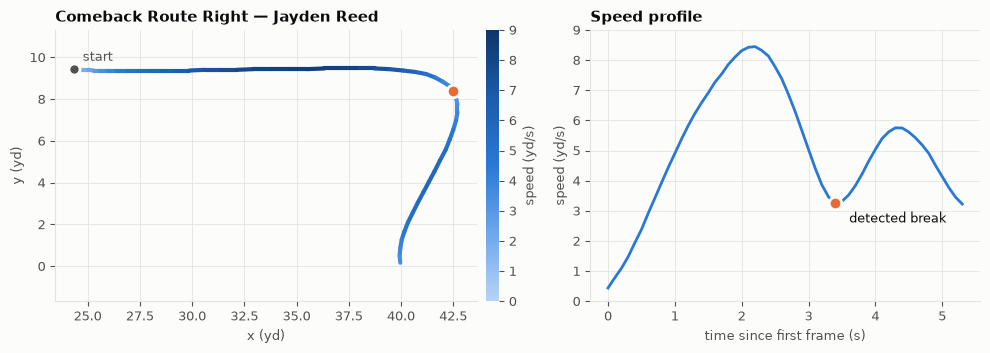

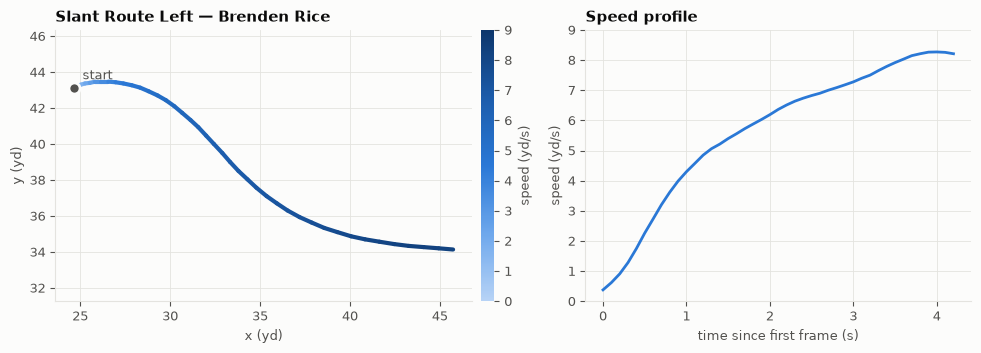

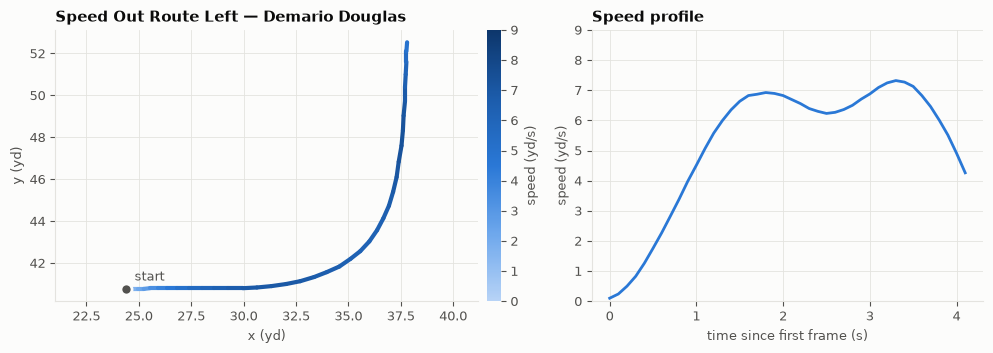

In [13]:
events = sketch_break_metrics(ct)
example_ids = {}
for drill in ["COMEBACK_ROUTE_RIGHT", "SLANT_ROUTE_LEFT", "SPEED_OUT_ROUTE_LEFT"]:
    ev = ctp.filter(pl.col("drill_name") == drill)
    # median-length attempt: a typical rep, not a cherry-picked one
    lens = ev.group_by("event_id").len().sort("len", "event_id")
    example_ids[drill] = lens["event_id"][lens.height // 2]

for i, (drill, eid) in enumerate(example_ids.items(), 1):
    tr = ctp.filter(pl.col("event_id") == eid).sort("time")
    name = players.filter(pl.col("nfl_id") == tr["nfl_id"][0])["display_name"][0]
    hit = events.filter(pl.col("event_id") == eid)
    brk = int(hit["break_frame"][0]) if drill in SPEED_DIP_DRILLS and hit.height else None
    fig = plot_drill_trace(tr, f"{drill.replace('_', ' ').title()} — {name}", break_frame=brk)
    fig.savefig(FIG_PATH / f"p1_trace_{i}_{drill.lower()}.png", dpi=150)
    plt.show()

## 4. NFL play table

Proposed base filter: `season_type == 'REG'` and `play_nullified_by_penalty == 'N'`.

In [14]:
pp = regular_season(pp_all)
print(f"rows: all={pp_all.height:,}  after REG + not-nullified filter={pp.height:,}")
OUTCOMES = ["separation_at_pass_forward", "route_ran", "cushion", "player_get_off",
            "time_to_pressure", "pressure_allowed", "coverage_assignment"]
(pp.group_by("nfl_position")
   .agg(pl.len().alias("rows"), pl.col("nfl_id").n_unique().alias("players"),
        *[pl.col(c).is_not_null().mean().round(2).alias(c) for c in OUTCOMES])
   .sort("rows", descending=True))

rows: all=314,197  after REG + not-nullified filter=240,412


nfl_position,rows,players,separation_at_pass_forward,route_ran,cushion,player_get_off,time_to_pressure,pressure_allowed,coverage_assignment
str,u32,u32,f64,f64,f64,f64,f64,f64,f64
"""G""",37470,39,0.0,0.0,0.0,0.0,0.0,0.58,0.0
"""WR""",34889,82,0.88,1.0,0.95,0.0,0.0,0.0,0.0
"""CB""",34760,50,0.0,0.0,0.92,0.0,0.0,0.0,0.61
"""T""",34729,37,0.0,0.0,0.0,0.0,0.0,0.59,0.0
"""SS""",18529,24,0.0,0.0,0.35,0.01,0.01,0.0,0.63
"""DE""",17493,30,0.0,0.0,0.01,0.72,0.06,0.0,0.58
"""OLB""",16598,26,0.0,0.0,0.22,0.68,0.06,0.0,0.6
"""DT""",14392,37,0.0,0.0,0.0,0.6,0.04,0.0,0.56
"""C""",10649,15,0.0,0.0,0.0,0.0,0.0,0.59,0.0


Each outcome lives in one position family: `separation_at_pass_forward` / `route_ran` for WR/TE,
`player_get_off` for the pass rush (DE/OLB/DT), `pressure_allowed` for OL. **There is no
"separation allowed" label for DBs**, only `cushion` and `coverage_assignment`.

In [15]:
wr = wr_route_snaps(pp)
print(f"WR route snaps with separation: {wr.height:,} | targeted: {wr['target'].sum():,} | players: {wr['nfl_id'].n_unique()}")
wr_ps = wr.group_by("nfl_id", "season", "draft_year").agg(pl.len().alias("routes"), pl.col("target").sum().alias("targets"))
(wr_ps.with_columns((pl.col("season") - pl.col("draft_year") + 1).alias("nfl_year"))
      .group_by("draft_year", "nfl_year")
      .agg(pl.len().alias("player_seasons"), pl.col("routes").median().alias("median_routes"),
           (pl.col("routes") >= 100).sum().alias("seasons_100plus_routes"))
      .sort("draft_year", "nfl_year"))

WR route snaps with separation: 30,566 | targeted: 6,433 | players: 82


draft_year,nfl_year,player_seasons,median_routes,seasons_100plus_routes
i64,i64,u32,f64,u32
2023,1,29,197.0,22
2023,2,27,209.0,19
2023,3,23,213.0,14
2024,1,27,175.0,15
2024,2,20,243.0,15
2025,1,23,162.0,15


In [16]:
fam = (wr.with_columns(pl.when(pl.col("route_ran").is_in(BREAKING_ROUTES)).then(pl.lit("breaking"))
                         .when(pl.col("route_ran").is_in(VERTICAL_ROUTES)).then(pl.lit("vertical"))
                         .otherwise(pl.lit("other")).alias("family")))
fam.group_by("family", "route_ran").agg(
    pl.len().alias("snaps"),
    pl.col("separation_at_pass_forward").mean().round(2).alias("mean_sep"),
    pl.col("target").mean().round(3).alias("target_rate"),
).sort("family", "snaps", descending=[False, True])

family,route_ran,snaps,mean_sep,target_rate
str,str,u32,f64,f64
"""breaking""","""HITCH""",4941,3.07,0.224
"""breaking""","""IN""",3381,2.94,0.15
"""breaking""","""OUT""",2959,3.02,0.317
"""breaking""","""CORNER""",2487,2.95,0.128
"""breaking""","""SLANT""",2088,2.79,0.267
"""other""","""CROSS""",3754,3.32,0.239
"""other""","""SCREEN""",940,6.66,0.682
"""other""","""FLAT""",853,4.53,0.225
"""other""","""WHEEL""",47,3.55,0.255


In [17]:
# Context controls available on WR route snaps
wr.select(
    pl.col("cushion").is_not_null().mean().alias("cushion_nonnull"),
    pl.col("team_coverage_man_zone").is_not_null().mean().alias("coverage_nonnull"),
    (pl.col("team_coverage_man_zone") == "MAN_COVERAGE").mean().alias("man_share"),
    pl.col("lined_up_position").eq("SLOT_WR").mean().alias("slot_share"),
    pl.corr("cushion", "separation_at_pass_forward", method="spearman").alias("rho_cushion_sep"),
).with_columns(pl.all().round(3))

cushion_nonnull,coverage_nonnull,man_share,slot_share,rho_cushion_sep
f64,f64,f64,f64,f64
0.949,1.0,0.277,0.35,0.355


**Size is a confounder.** Player-level mean separation (WRs with ≥100 REG routes) against body size and
the 40. Bigger receivers get less separation, which may partly reflect the routes they are asked to run.
Height and weight must be controls in Phase 4.

In [18]:
def fisher_ci(r, n):
    z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)

wr_sep = (wr.group_by("nfl_id").agg(pl.len().alias("routes"), pl.col("separation_at_pass_forward").mean().alias("sep"))
            .filter(pl.col("routes") >= 100)
            .join(cr.filter(pl.col("combine_position") == "WR"), on="nfl_id"))
rows = []
for c in ["combine_height", "combine_weight", "forty", "ten_yd_split"]:
    z = wr_sep.select(c, "sep").drop_nulls()
    r = float(np.corrcoef(z[c], z["sep"])[0, 1])
    lo, hi = fisher_ci(r, z.height)
    rows.append({"combine_metric": c, "n": z.height, "pearson_r": round(r, 2), "ci95_lo": round(lo, 2), "ci95_hi": round(hi, 2)})
pl.DataFrame(rows)

combine_metric,n,pearson_r,ci95_lo,ci95_hi
str,i64,f64,f64,f64
"""combine_height""",62,-0.56,-0.71,-0.36
"""combine_weight""",62,-0.57,-0.72,-0.38
"""forty""",57,-0.21,-0.45,0.05
"""ten_yd_split""",57,-0.23,-0.46,0.03


### 4b. Game tracking (scanned, never fully loaded)

Event frames only, scanned year by year.

In [19]:
gt_events = (scan_game_tracking().filter(pl.col("event").is_not_null())
             .group_by("event").agg(pl.len().alias("frames")).sort("frames", descending=True).collect())
gt_ids = scan_game_tracking().select(pl.col("nfl_id").unique()).collect()["nfl_id"]
gt_plays = scan_game_tracking().select(pl.struct("game_id", "play_id", "nfl_id").n_unique()).collect().item()
print(f"distinct nfl_id in game tracking: {gt_ids.len()} (all in cohort: {gt_ids.is_in(players['nfl_id'].implode()).all()})")
print(f"distinct player-plays tracked: {gt_plays:,} vs player_play rows: {pp_all.height:,}")
gt_events.head(8)

distinct nfl_id in game tracking: 497 (all in cohort: True)
distinct player-plays tracked: 314,944 vs player_play rows: 314,197


event,frames
str,u32
"""ball_snap""",314278
"""pass_forward""",187479
"""first_contact""",184368
"""tackle""",184269
"""pass_arrived""",141322
"""pass_outcome_caught""",113171
"""handoff""",92594
"""pass_outcome_incomplete""",64869


Game tracking contains **only the 510 cohort players** (no teammates, opponents or ball).
Separation cannot be recomputed from it, so `separation_at_pass_forward` in `player_play` is the outcome
of record; game tracking can add the receiver's own movement (e.g. speed at the break) in Phase 3.

## 5. Overlap: position × Combine tracking × NFL outcome

Outcome per group: WR/TE `separation_at_pass_forward`; DB `cushion` (proxy only); DL `player_get_off`;
OL `pressure_allowed`. REG season, not nullified.

In [20]:
OUTCOME_BY_GROUP = {"WR": "separation_at_pass_forward", "TE": "separation_at_pass_forward",
                    "DB": "cushion", "DL": "player_get_off", "OL": "pressure_allowed"}
SKILL = {"WR": "SKILL_DRILLS_WR", "TE": "SKILL_DRILLS_TE", "DB": "SKILL_DRILLS_DB",
         "DL": "SKILL_DRILLS_DL", "OL": "SKILL_DRILLS_OL"}

has_skill = ctp.select("nfl_id", "drill_type").unique()
rows = []
for grp, outcome in OUTCOME_BY_GROUP.items():
    ids = cr.filter(pl.col("combine_position") == grp)["nfl_id"]
    skill_ids = has_skill.filter((pl.col("drill_type") == SKILL[grp]) & pl.col("nfl_id").is_in(ids.implode()))["nfl_id"].unique()
    n_out = (pp.filter(pl.col("nfl_id").is_in(ids.implode()) & pl.col(outcome).is_not_null())
               .group_by("nfl_id").len())
    for min_plays in (1, 100):
        out_ids = n_out.filter(pl.col("len") >= min_plays)["nfl_id"]
        rows.append({"group": grp, "outcome": outcome, "min_plays": min_plays, "players": ids.len(),
                     "skill_tracking": skill_ids.len(), "nfl_outcome": out_ids.len(),
                     "both": skill_ids.is_in(out_ids.implode()).sum(),
                     "outcome_plays_for_both": n_out.filter(pl.col("nfl_id").is_in(skill_ids.implode())
                                                           & (pl.col("len") >= min_plays))["len"].sum()})
overlap = pl.DataFrame(rows)
overlap

group,outcome,min_plays,players,skill_tracking,nfl_outcome,both,outcome_plays_for_both
str,str,i64,i64,i64,i64,i64,i64
"""WR""","""separation_at_pass_forward""",1,107,107,83,83,31035
"""WR""","""separation_at_pass_forward""",100,107,107,63,63,30347
"""TE""","""separation_at_pass_forward""",1,42,42,33,33,6781
"""TE""","""separation_at_pass_forward""",100,42,42,21,21,6499
"""DB""","""cushion""",1,122,122,93,93,40485
"""DB""","""cushion""",100,122,122,57,57,39134
"""DL""","""player_get_off""",1,118,114,98,95,31499
"""DL""","""player_get_off""",100,118,114,69,66,30191
"""OL""","""pressure_allowed""",1,121,121,89,89,48697


## 6. Tracking vs stopwatch — sketch only

A deliberately crude break metric on the two drills with a single speed-dip break
(`COMEBACK_ROUTE_RIGHT`, `CURL_ROUTE_RIGHT`): peak deceleration into the break, peak
acceleration out of it (first 0.5 s), and break time. Best attempt per player.
This is **not** the Phase 2 metric. It only answers "is this a 1:1 proxy of the stopwatch?".
We deliberately do **not** look at NFL outcomes yet, to avoid tuning the metric on the target.

In [21]:
n_total = ctp.filter(pl.col("drill_name").is_in(SPEED_DIP_DRILLS))["event_id"].n_unique()
print(f"break detected in {events.height} / {n_total} attempts")
best = player_best(events)
METRICS = ["peak_decel", "exit_accel", "break_time_s"]
BASE = ["three_cone", "short_shuttle", "forty", "ten_yd_split", "ngs_athleticism_score"]
out = []
for drill in SPEED_DIP_DRILLS:
    d = best.filter(pl.col("drill_name") == drill).join(cr, on="nfl_id")
    for m in METRICS:
        row = {"drill": drill, "metric": m, "players": d.height}
        for b in BASE:
            z = d.select(m, b).drop_nulls()
            row[f"rho_{b}"] = round(spearmanr(z[m], z[b]).statistic, 2)
            row[f"n_{b}"] = z.height
        out.append(row)
proxy = pl.DataFrame(out)
proxy.select("drill", "metric", "players", *[c for c in proxy.columns if c.startswith("rho_")],
             "n_three_cone", "n_short_shuttle")

break detected in 189 / 220 attempts


drill,metric,players,rho_three_cone,rho_short_shuttle,rho_forty,rho_ten_yd_split,rho_ngs_athleticism_score,n_three_cone,n_short_shuttle
str,str,i64,f64,f64,f64,f64,f64,i64,i64
"""COMEBACK_ROUTE_RIGHT""","""peak_decel""",83,-0.35,-0.17,-0.13,-0.16,0.08,28,32
"""COMEBACK_ROUTE_RIGHT""","""exit_accel""",83,-0.11,-0.1,-0.15,-0.12,0.07,28,32
"""COMEBACK_ROUTE_RIGHT""","""break_time_s""",83,-0.48,-0.26,-0.07,-0.02,0.07,28,32
"""CURL_ROUTE_RIGHT""","""peak_decel""",100,-0.37,-0.32,-0.1,-0.06,0.09,30,35
"""CURL_ROUTE_RIGHT""","""exit_accel""",100,-0.38,-0.2,-0.17,-0.08,0.13,30,35
"""CURL_ROUTE_RIGHT""","""break_time_s""",100,0.21,0.23,0.11,0.08,-0.18,30,35


In [22]:
# Cross-drill consistency of the same trait (same player, comeback vs curl): a reliability proxy
pair = (best.filter(pl.col("drill_name") == SPEED_DIP_DRILLS[0])
            .join(best.filter(pl.col("drill_name") == SPEED_DIP_DRILLS[1]), on="nfl_id", suffix="_curl"))
pl.DataFrame([{"metric": m, "players": pair.height,
               "rho_comeback_vs_curl": round(spearmanr(pair[m], pair[f"{m}_curl"]).statistic, 2)}
              for m in METRICS + ["entry_speed"]])

metric,players,rho_comeback_vs_curl
str,i64,f64
"""peak_decel""",81,0.31
"""exit_accel""",81,0.2
"""break_time_s""",81,-0.27
"""entry_speed""",81,0.36


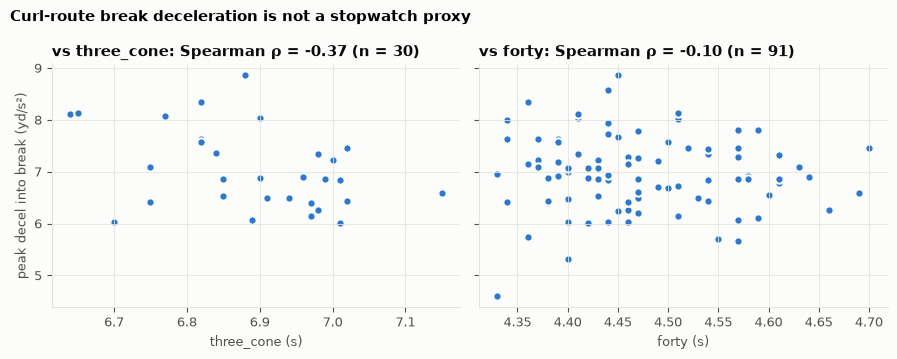

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
d = best.filter(pl.col("drill_name") == "CURL_ROUTE_RIGHT").join(cr, on="nfl_id")
for ax, b in zip(axes, ["three_cone", "forty"]):
    z = d.select("peak_decel", b).drop_nulls()
    ax.scatter(z[b], z["peak_decel"], s=36, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1.5)
    ax.set_xlabel(f"{b} (s)")
    rho = spearmanr(z[b], z["peak_decel"]).statistic
    ax.set_title(f"vs {b}: Spearman ρ = {rho:+.2f} (n = {z.height})")
axes[0].set_ylabel("peak decel into break (yd/s²)")
fig.suptitle("Curl-route break deceleration is not a stopwatch proxy", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_PATH / "p1_decel_vs_stopwatch.png", dpi=150)
plt.show()

## 7. Thesis lock memo

**Recommendation: lock the default thesis.** WR Combine break mechanics → NFL
`separation_at_pass_forward` on regular-season route-running snaps. Neither backup is safer.

| Check | Default: WR breaks → separation | Result |
|---|---|---|
| Combine drill coverage | 107/107 Combine WRs have `SKILL_DRILLS_WR` tracking: 15 route drills, 0.10 s sampling throughout, one player per event. Named drills with fixed geometry (comeback, curl, slant, speed-out, dagger) each cover 75–107 WRs. The speed-dip break detector fires on 189/220 comeback + curl attempts. | **PASS** |
| Sample size | 83 of 107 WRs have drill tracking and ≥1 REG route snap with separation; 63 have ≥100 career REG routes. That is about 31K REG route snaps with separation, ~6.4K of them targeted. Breaking routes (HITCH, IN, OUT, CORNER, SLANT) are 52% of routes. | **PASS, but thin** (player-level N ≈ 63–83) |
| Tracking > stopwatch | Sketch break metrics have \|ρ\| ≤ 0.5 against 3-cone and shuttle (n ≈ 25–35), and \|ρ\| ≤ 0.2 against forty, 10-yd split and the NGS athleticism score (n ≈ 70–100). And 69% of WRs skipped the 3-cone (65% the shuttle), so for most WRs tracking is the *only* agility measure. | **PASS** |
| Confounders we can name | **Body size**: height r = −0.56 and weight r = −0.57 with player-level separation (§4); draft pick / UDFA (`players`); route volume & target share; route mix (`route_ran`); `cushion` (95% non-null on WR routes; Spearman ρ = 0.36 with separation); `team_coverage_man_zone`; slot vs wide (`lined_up_position`); draft class (2025 rookies have one season); conference. | **PASS** |

**Why not the backups:**
- *Backup A (DB transition → coverage):* there is no "separation allowed" label for DBs in `player_play`, and game
  tracking holds only cohort players, so we can't measure a defender's distance to the receiver. The outcome would
  be a proxy (`cushion`), which fails the "regular-season performance" bar.
- *Backup B (DL get-off):* the outcome is clean (`player_get_off` on 60–72% of REG DE/OLB/DT snaps; 95 DL have drill tracking and the outcome, 66 with ≥100 plays). That is slightly *more* players than WR, but the
  Combine signal overlaps heavily with the 10-yd split. That makes it the more "obvious" idea. A public audit notebook
  also reports that the 10-yd split vs get-off link (r ≈ 0.67) falls to about 0.35 once weight is held fixed (not
  re-verified here). Keep it as the fallback if the WR metric fails reliability in Phase 2.

**Risks to carry into Phase 2 (must be addressed, not hidden):**
1. **Reliability.** Each WR usually runs each route drill once, so within-drill test-retest is impossible. The
   naive sketch metrics agree only weakly across drills (comeback vs curl: ρ ≈ 0.31 for peak decel, ≈ 0.2 for
   exit accel, and break time even flips sign). Phase 2 needs a better-defined, geometry-aware break metric,
   pooled across several breaking drills (comeback, curl, speed-out, dagger, post-corner), and must report
   its cross-drill reliability.
2. **Small N.** About 63–83 players. Use rank correlations, nested OLS with CIs and leave-one-draft-class-out.
   No ML.
3. **Opportunity / survivor bias.** 24 of 107 Combine WRs never ran a REG route in the data, and playing time is
   chosen by coaches. Players with few routes are noisy. Weight or shrink by route count, and report who drops out
   (by draft round).
4. **Stopwatch baseline N.** Only ~30 WRs have a 3-cone, so "beyond 3-cone" comparisons need that caveat. Forty and
   10-yd split (~91% present) are the realistic stopwatch controls.

**Plan amendments for Phase 2–4** (from the Phase 1 data plus a public Combine-tracking audit notebook):
1. **Path geometry from `x`/`y` only.** Never sum `dis` (see §1).
2. **Reliability is the first gate.** Before any NFL linkage, report each candidate cut metric's cross-drill
   agreement (comeback, curl, speed-out, dagger, post-corner) within WRs. The audit found WR start burst barely
   repeats between two 40 attempts (peak accel r ≈ 0.02), while top speed repeats (r ≈ 0.9). A metric that doesn't
   repeat can't correlate with anything a season later.
3. **Pre-register one primary test.** Pick one cut metric and one outcome (player-level separation on breaking
   routes) before looking at NFL data. With ~60 WRs, one pre-chosen test needs \|r\| ≥ 0.26 for p < 0.05, and a search
   across many metrics needs ~0.4. Anything else is labelled exploratory, judged against a shuffled-outcome bar.
4. **Positive control.** Tracked Combine top speed vs NFL in-game top speed for WRs. The audit reports r ≈ 0.59.
   Reproducing it shows the pipeline can find a real link.
5. **Controls in Phase 4:** height and weight, the forty / 10-yd split, draft pick, route mix, cushion, man/zone
   coverage, and slot vs wide. Report Fisher or bootstrap 95% CIs, check results within each draft class, and
   compare WRs only with other WRs.

**Proposed filters:** REG season only; drop `play_nullified_by_penalty == 'Y'`; a route-running WR snap is
`route_ran` non-null with `separation_at_pass_forward` non-null (all routes, not just targets). Targets are
reported as a sub-analysis.

*Stopping here, per NEXT_STEPS.md §6. Waiting for a "thesis locked" message before Phase 2.*